In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
sns.set_style("whitegrid")

In [2]:
df = pd.read_csv('../data/sample_data.csv')
df['datetime'] = pd.to_datetime(df['date_time'])
df['date'] = pd.to_datetime(df['date'])
print(f'数据加载完成，总计{len(df)}条数据')

数据加载完成，总计5025843条数据


In [3]:
user_behaviors = df.groupby('user_id')['behavior_type'].unique()
pv_users = set(df[df['behavior_type'] == 'pv']['user_id'].unique())
fav_cart_users = set(df[df['behavior_type'].isin(['fav','cart'])]['user_id'].unique())
buy_users = set(df[df['behavior_type'] == 'buy']['user_id'].unique())

funnel_layer1 = len(pv_users)
funnel_layer2 = len(pv_users & fav_cart_users)
funnel_layer3 = len(pv_users & fav_cart_users & buy_users)
direct_buy = len(buy_users - fav_cart_users)

funnel_data = pd.DataFrame({
    '环节' : ['浏览用户','加购/收藏用户','购买用户'],
    '用户数' : [funnel_layer1,funnel_layer2,funnel_layer3]
})
funnel_data['环比转化率(%)'] = [
    round(funnel_layer1 / df['user_id'].nunique() * 100,2),
    round(funnel_layer2 / funnel_layer1 * 100,2),
    round(funnel_layer3 / funnel_layer2 * 100,2)
]
funnel_data['整体转化率(%)'] = [
    round(funnel_layer1 / df['user_id'].nunique() * 100,2),
    round(funnel_layer2 / funnel_layer1 * 100,2),
    round(funnel_layer3 / funnel_layer1 * 100,2)
]
print(funnel_data.to_string(index=False))
print(f"\n直接购买用户（未加购/收藏直接购买）: {direct_buy} 人")
print(f"直接购买占总购买用户比例: {direct_buy/len(buy_users)*100:.1f}%")

     环节   用户数  环比转化率(%)  整体转化率(%)
   浏览用户 49800     99.60     99.60
加购/收藏用户 43221     86.79     86.79
   购买用户 30352     70.23     60.95

直接购买用户（未加购/收藏直接购买）: 3515 人
直接购买占总购买用户比例: 10.3%


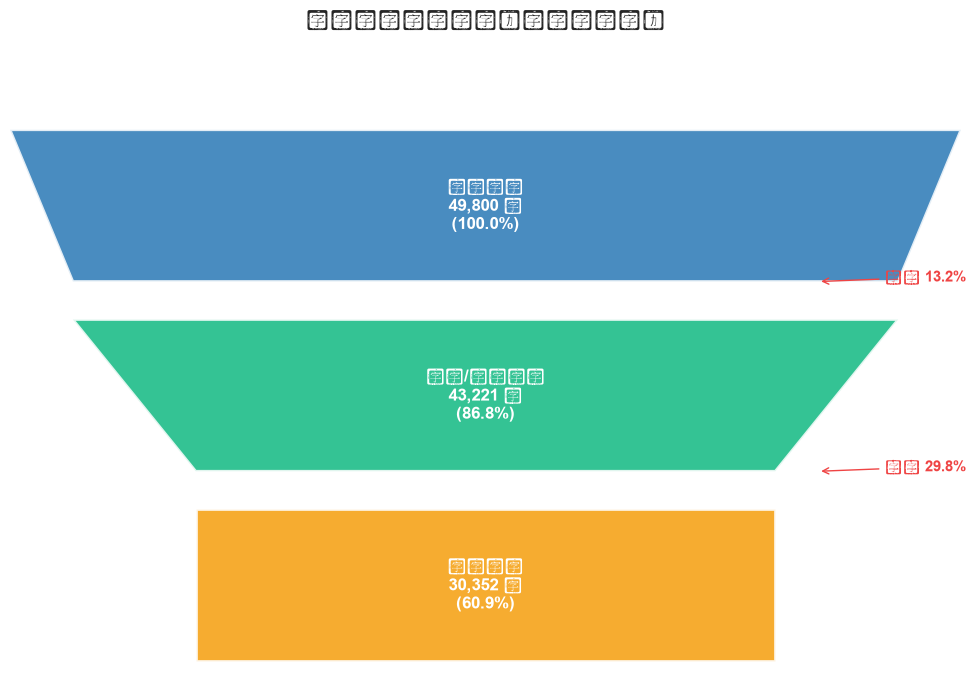

In [4]:
fig, ax = plt.subplots(figsize=(10, 7))
stages = ['浏览用户', '加购/收藏用户', '购买用户']
values = [funnel_layer1, funnel_layer2, funnel_layer3]
colors = ['#2978B5', '#10B981', '#F59E0B']
max_val = values[0]
widths = [v / max_val for v in values]
y_positions = [3, 2, 1]
height = 0.8

for i in range(len(stages)):
    y = y_positions[i]
    w = widths[i]
    left = (1 - w) / 2
    right = left + w
    if i < len(stages) - 1:
        w_next = widths[i + 1]
        left_next = (1 - w_next) / 2
        right_next = left_next + w_next
    else:
        left_next = left
        right_next = right
    x = [left, right, right_next, left_next]
    y_trap = [y + height/2, y + height/2, y - height/2, y - height/2]
    ax.fill(x, y_trap, color=colors[i], alpha=0.85, edgecolor='white', linewidth=2)
    ax.text(0.5, y,
            f'{stages[i]}\n{values[i]:,} 人\n({values[i]/max_val*100:.1f}%)',
            ha='center', va='center',
            fontsize=12, fontweight='bold', color='white')
    if i < len(stages) - 1:
        drop_rate = (1 - values[i+1] / values[i]) * 100
        ax.annotate(f'流失 {drop_rate:.1f}%',
                    xy=(0.85, y - height/2),
                    xytext=(0.92, y - height/2),
                    fontsize=11, color='#EF4444', fontweight='bold',
                    arrowprops=dict(arrowstyle='->', color='#EF4444'))
ax.set_xlim(0, 1)
ax.set_ylim(0.5, 3.8)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('用户转化漏斗分析（按用户去重）',
             fontsize=15, fontweight='bold', pad=20)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.savefig('../data/04_conversion_funnel.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
user_count = df['user_id'].nunique()
funnel_detail = pd.DataFrame({
    '环节':['浏览','加购/收藏','购买'],
    '用户数':[funnel_layer1, funnel_layer2, funnel_layer3]
})
funnel_detail['流失人数'] = [
    user_count - funnel_layer1,
    funnel_layer1 - funnel_layer2,
    funnel_layer2 - funnel_layer3
]
funnel_detail['环比流失率(%)'] = [
    (user_count - funnel_layer1) / user_count * 100,
    (funnel_layer1 - funnel_layer2) / funnel_layer1 * 100,
    (funnel_layer2 - funnel_layer3) / funnel_layer2 * 100
]
funnel_detail['占比流失率(%)'] = [
    (user_count - funnel_layer1) / (user_count - funnel_layer3) * 100,
    (funnel_layer1 - funnel_layer2) / (user_count - funnel_layer3) * 100,
    (funnel_layer2-funnel_layer3) / (user_count - funnel_layer3) * 100
]
print(funnel_detail.to_string(index = False,float_format = '%.2f'))
churn_layer1 = (funnel_layer1 - funnel_layer2) / funnel_layer1 * 100
churn_layer2 = (funnel_layer2 - funnel_layer3) / funnel_layer2 * 100

print("\n核心发现：")
print(f"- 浏览→加购/收藏环节流失率: {churn_layer1:.1f}%，流失 {funnel_layer1 - funnel_layer2:,} 人")
print(f"- 加购/收藏→购买环节流失率: {churn_layer2:.1f}%，流失 {funnel_layer2 - funnel_layer3:,} 人")

if churn_layer1 > churn_layer2:
    print(f"\n👉 核心流失环节: 浏览→加购/收藏（流失率更高）")
    print("   优化方向: 提升商品吸引力、优化详情页、推荐更精准")
else:
    print(f"\n👉 核心流失环节: 加购/收藏→购买（流失率更高）")
    print("   优化方向: 促销活动、优惠券、简化结算流程、减少运费")

   环节   用户数  流失人数  环比流失率(%)  占比流失率(%)
   浏览 49800   200      0.40      1.02
加购/收藏 43221  6579     13.21     33.48
   购买 30352 12869     29.77     65.50

核心发现：
- 浏览→加购/收藏环节流失率: 13.2%，流失 6,579 人
- 加购/收藏→购买环节流失率: 29.8%，流失 12,869 人

👉 核心流失环节: 加购/收藏→购买（流失率更高）
   优化方向: 促销活动、优惠券、简化结算流程、减少运费


In [6]:
hourly_user = df.drop_duplicates(subset = ['user_id','hour','behavior_type'])
hourly_pivot = hourly_user.pivot_table(
    index = 'hour',
    columns = 'behavior_type',
    values = 'user_id',
    aggfunc = 'nunique',
    fill_value = 0
)

hourly_pivot['fav_cart'] = hourly_pivot['fav'] + hourly_pivot['cart']
hourly_pivot['浏览-加购/收藏转化率(%)'] = (
    hourly_pivot['fav_cart'] / hourly_pivot['pv'] * 100
).round(2)
hourly_pivot['浏览-购买转化率(%)'] = (
    hourly_pivot['buy'] / hourly_pivot['pv'] * 100
).round(2)

print('各小时转化率')
print(hourly_pivot[['浏览-加购/收藏转化率(%)','浏览-购买转化率(%)']])

print("\n购买转化率最高的3个时段：")
print(hourly_pivot['浏览-购买转化率(%)'].nlargest(3))
print("\n购买转化率最低的3个时段：")
print(hourly_pivot['浏览-购买转化率(%)'].nsmallest(3))

各小时转化率
behavior_type  浏览-加购/收藏转化率(%)  浏览-购买转化率(%)
hour                                      
0                       36.81        11.50
1                       38.10        14.76
2                       39.18        16.60
3                       38.92        15.69
4                       37.42        15.24
5                       39.70        15.96
6                       39.31        15.84
7                       39.41        15.64
8                       39.38        14.99
9                       38.13        13.63
10                      37.64        12.86
11                      40.85        14.56
12                      44.72        15.34
13                      47.89        15.72
14                      49.97        15.55
15                      51.41        14.16
16                      43.21        12.24
17                      40.48         9.91
18                      38.10         7.60
19                      36.48         7.12
20                      33.73         7.41
21  

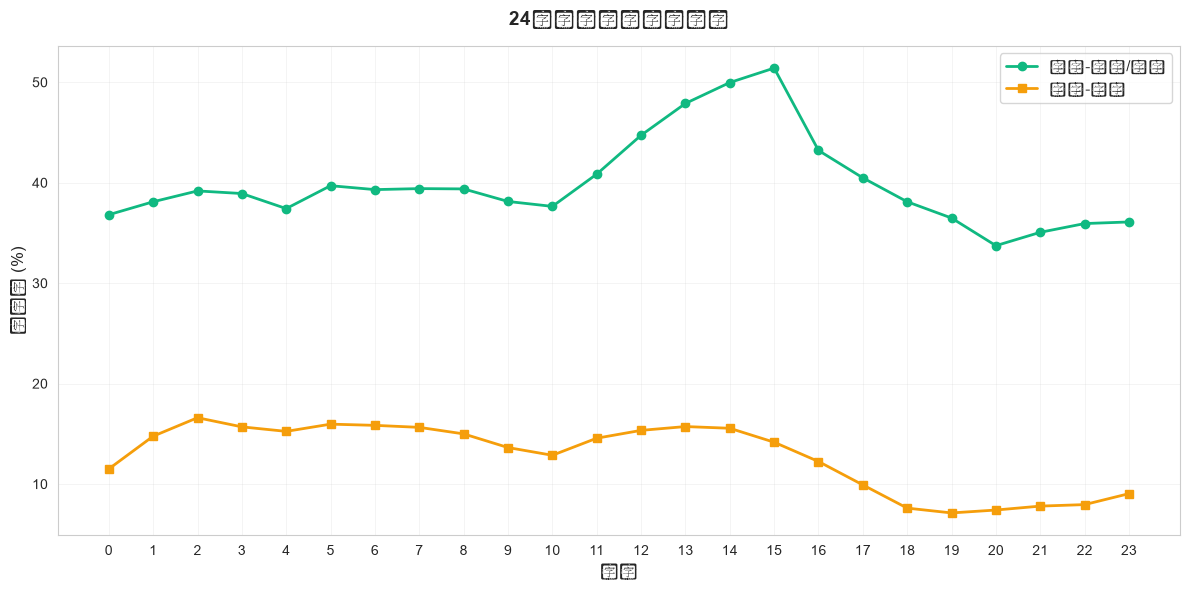

In [7]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(hourly_pivot.index, hourly_pivot['浏览-加购/收藏转化率(%)'],
        marker='o', linewidth=2, color='#10B981', label='浏览-加购/收藏')
ax.plot(hourly_pivot.index, hourly_pivot['浏览-购买转化率(%)'],
        marker='s', linewidth=2, color='#F59E0B', label='浏览-购买')

ax.set_xlabel('小时', fontsize=12)
ax.set_ylabel('转化率 (%)', fontsize=12)
ax.set_title('24小时转化率变化趋势', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(range(0, 24))
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../data/04_hourly_conversion.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
daily_user = df.drop_duplicates(subset=['user_id','date','behavior_type'])
daily_pivot = daily_user.pivot_table(
    index = 'date',
    columns = 'behavior_type',
    values = 'user_id',
    aggfunc = 'nunique',
    fill_value = 0
)
daily_pivot['fav_cart'] = daily_pivot['fav'] + daily_pivot['cart']
daily_pivot['pv-buy'] = (daily_pivot['buy'] / daily_pivot['pv'] * 100).round(2)
daily_pivot['fav_cart-buy'] = (daily_pivot['buy'] / daily_pivot['fav_cart'] * 100).round(2)
print('每日转化率')
print(daily_pivot[['pv','cart','buy','pv-buy','fav_cart']])

每日转化率
behavior_type     pv   cart   buy  pv-buy  fav_cart
date                                               
2017-11-25     34686  12160  6668   19.22     18112
2017-11-26     34983  12444  7123   20.36     18255
2017-11-27     34948  11802  7281   20.83     17597
2017-11-28     34668  11770  7097   20.47     17564
2017-11-29     35308  12085  7463   21.14     17868
2017-11-30     36066  12405  7401   20.52     18321
2017-12-01     37066  13580  7280   19.64     19741
2017-12-02     46260  16710  8781   18.98     24263
2017-12-03     44757  14883  8047   17.98     21729


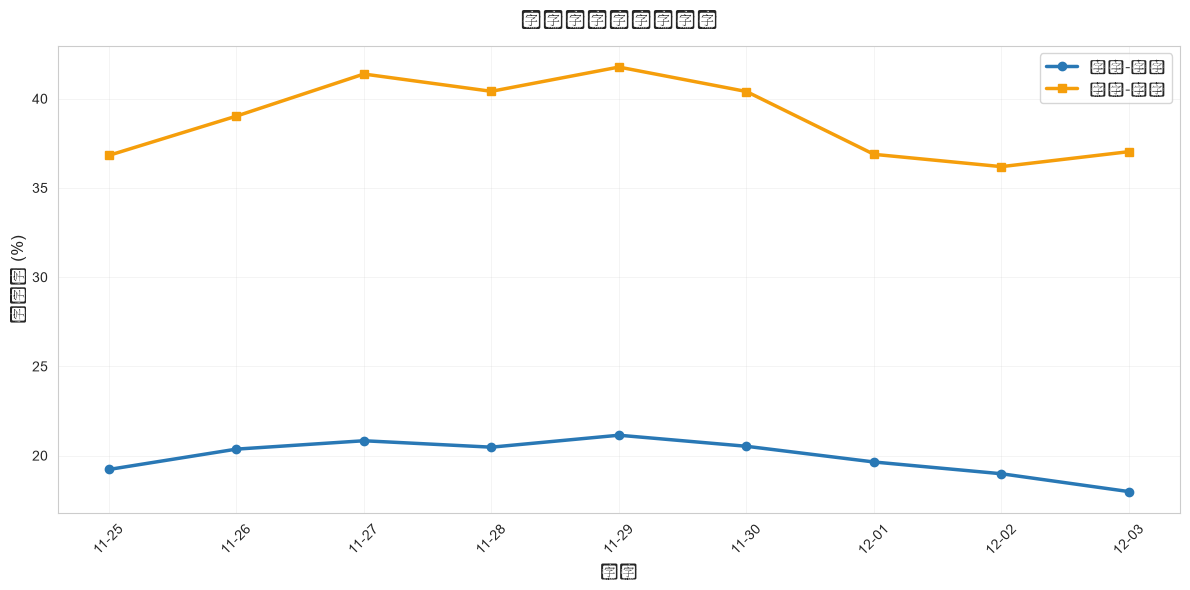

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

x_labels = [d.strftime('%m-%d') for d in daily_pivot.index]

ax.plot(x_labels, daily_pivot['pv-buy'],
        marker='o', linewidth=2.5, color='#2978B5', label='浏览-购买')
ax.plot(x_labels, daily_pivot['fav_cart-buy'],
        marker='s', linewidth=2.5, color='#F59E0B', label='加购-购买')

ax.set_xlabel('日期', fontsize=12)
ax.set_ylabel('转化率 (%)', fontsize=12)
ax.set_title('每日转化率变化趋势', fontsize=14, fontweight='bold', pad=15)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('../data/04_daily_conversion.png', dpi=150, bbox_inches='tight')
plt.show()

In [18]:
category_stats = df.groupby(['category_id', 'behavior_type'])['user_id'].nunique().unstack(fill_value=0)
category_stats = category_stats[category_stats['buy'] > 0]
top20_categories = category_stats['pv'].nlargest(20).index
category_top20 = category_stats.loc[top20_categories].copy()
category_top20['pv→buy(%)'] = (
    category_top20['buy'] / category_top20['pv'] * 100
).round(2)
category_top20['cart→buy(%)'] = (
    category_top20['buy'] / category_top20['cart'] * 100
).round(2)
category_top20 = category_top20.sort_values('pv→buy(%)', ascending=True)

print("Top20品类按购买转化率排序（升序）：")
print(category_top20[['pv', 'cart', 'buy', 'pv→buy(%)', 'cart→buy(%)']])

Top20品类按购买转化率排序（升序）：
behavior_type     pv  cart   buy  pv→buy(%)  cart→buy(%)
category_id                                             
154040          7567   811    97       1.28        11.96
2920476         8171   913   109       1.33        11.94
1080785        11347  1366   202       1.78        14.79
2355072        18137  3136   488       2.69        15.56
2520377        14980  2448   406       2.71        16.58
3607361        16654  2768   546       3.28        19.73
4181361         8330  1675   335       4.02        20.00
1320293        17291  3055   758       4.38        24.81
2465336        13142  2422   589       4.48        24.32
149192          9950  1873   499       5.02        26.64
2520771         8885  1403   471       5.30        33.57
982926         19733  4297  1093       5.54        25.44
3002561        12775  2444   715       5.60        29.26
4217906        10043  1875   569       5.67        30.35
4756105        20625  4857  1234       5.98        25.41
4801426   

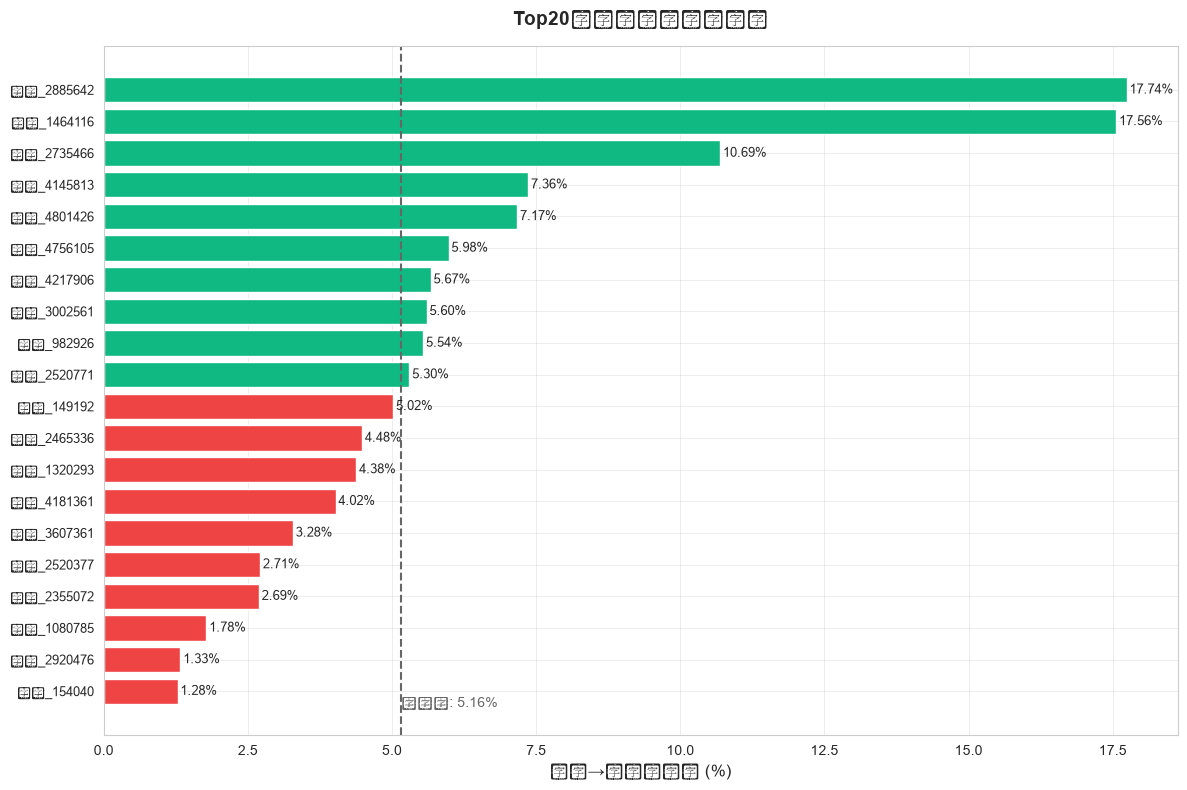

In [20]:
fig, ax = plt.subplots(figsize=(12, 8))

y_pos = range(len(category_top20))
colors = ['#EF4444' if v < category_top20['pv→buy(%)'].median()
          else '#10B981'
          for v in category_top20['pv→buy(%)']]

bars = ax.barh(y_pos, category_top20['pv→buy(%)'], color=colors)

ax.set_yticks(y_pos)
ax.set_yticklabels([f'品类_{c}' for c in category_top20.index], fontsize=9)
ax.set_xlabel('浏览→购买转化率 (%)', fontsize=12)
ax.set_title('Top20品类购买转化率排行', fontsize=14, fontweight='bold', pad=15)
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.05, bar.get_y() + bar.get_height()/2,
            f'{width:.2f}%', va='center', fontsize=9)
median_conv = category_top20['pv→buy(%)'].median()
ax.axvline(x=median_conv, color='#666', linestyle='--', linewidth=1.5)
ax.text(median_conv, -0.5, f'中位数: {median_conv:.2f}%',
        color='#666', fontsize=10)

plt.tight_layout()
plt.savefig('../data/04_category_conversion.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
user_activity = df.groupby('user_id').size().reset_index(name = 'total_actions')
user_buy = df[df['behavior_type'] == 'buy'].groupby('user_id').size().reset_index(name = 'buy_count')
user_activity = user_activity.merge(user_buy,on = 'user_id',how = 'left')
user_activity['has_buy'] = user_activity['buy_count'].notnull().astype(int)
user_activity['buy_count'] = user_activity['buy_count'].fillna(0)
user_activity['activity_level'] = pd.qcut(
    user_activity['total_actions'],
    q = 5,
    labels = ['低','较低','中','较高','高'],
)
activity_conv = user_activity.groupby('activity_level').agg(
    用户数 = ('user_id', 'nunique'),
    购买用户数 = ('has_buy', 'sum'),
    人均行为数 = ('total_actions','mean'),
    人均购买次数 = ('buy_count','mean')
)
activity_conv['购买转化率(%)'] = (
    activity_conv['购买用户数'] / activity_conv['用户数'] * 100
).round(2)

print("不同活跃度用户的购买转化率：")
print(activity_conv)

不同活跃度用户的购买转化率：
                  用户数  购买用户数       人均行为数    人均购买次数  购买转化率(%)
activity_level                                              
低               10455   5429   20.874605  1.014825     51.93
较低               9649   6071   45.654783  1.507203     62.92
中               10095   7062   75.369193  1.980684     69.96
较高               9863   7417  121.216668  2.417216     75.20
高                9938   8042  242.570336  3.244818     80.92


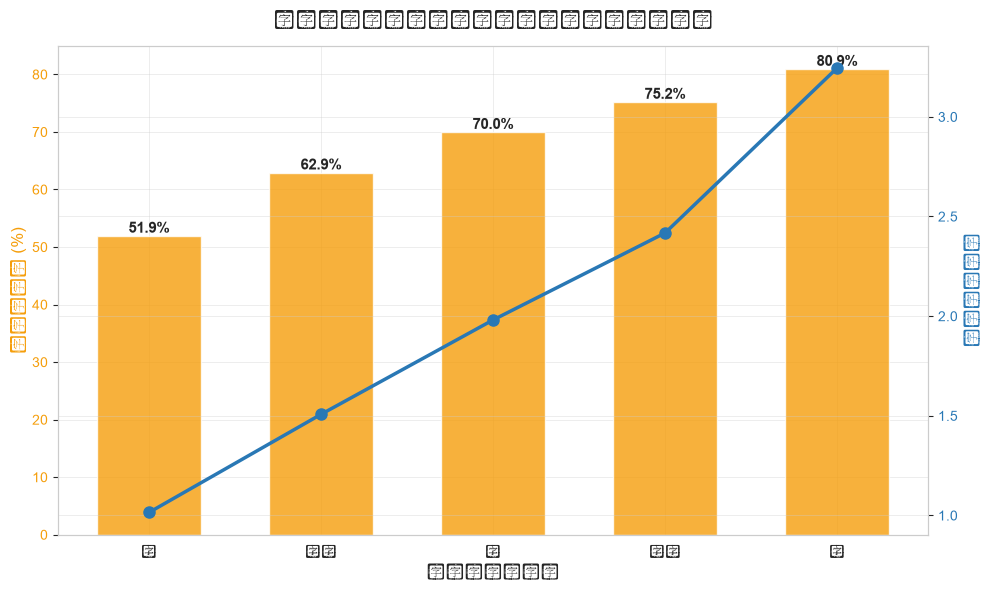

In [26]:
fig, ax1 = plt.subplots(figsize=(10, 6))
x = activity_conv.index
color1 = '#F59E0B'
ax1.set_xlabel('用户活跃度等级', fontsize=12)
ax1.set_ylabel('购买转化率 (%)', color=color1, fontsize=12)
bars = ax1.bar(x, activity_conv['购买转化率(%)'], color=color1,
               alpha=0.8, width=0.6)
ax1.tick_params(axis='y', labelcolor=color1)

for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height,
             f'{height:.1f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax2 = ax1.twinx()
color2 = '#2978B5'
ax2.set_ylabel('人均购买次数', color=color2, fontsize=12)
line = ax2.plot(x, activity_conv['人均购买次数'], color=color2,
                marker='o', linewidth=2.5, markersize=8)
ax2.tick_params(axis='y', labelcolor=color2)

ax1.set_title('不同活跃度用户的购买转化率与人均购买次数',
              fontsize=14, fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig('../data/04_activity_conversion.png', dpi=150, bbox_inches='tight')
plt.show()

In [37]:
buy_user_id = df[df['behavior_type'] == 'buy']['user_id'].unique()
print(f'购买用户总数：{len(buy_user_id)}')
first_buy = df[df['behavior_type'] == 'buy'].groupby('user_id')['datetime'].min().reset_index()
first_buy.columns = ['user_id','first_buy_time']
df_before_buy = df.merge(first_buy,on = 'user_id',how = 'inner')
df_before_buy = df_before_buy[df_before_buy['datetime'] < df_before_buy['first_buy_time']]
user_path = df_before_buy.groupby('user_id')['behavior_type'].unique()
path_dict = {
    '直接购买': 0,
    '仅收藏后购买': 0,
    '仅加购后购买': 0,
    '收藏+加购后购买': 0
}
for user_id,behaviors in user_path.items():
    has_fav = 'fav' in behaviors
    has_cart = 'cart' in behaviors
    if has_fav and has_cart:
        path_dict['收藏+加购后购买'] +=1
    elif has_fav:
        path_dict['仅收藏后购买'] += 1
    elif has_cart:
        path_dict['仅加购后购买'] += 1
    else:
        path_dict['直接购买'] += 1

path_df = pd.DataFrame(
    {'路径': path_dict.keys(), '用户数': path_dict.values()}
)
path_df['占比(%)'] = (path_df['用户数'] / path_df['用户数'].sum() * 100).round(2)
path_df = path_df.sort_values('用户数', ascending=False)

print("\n购买用户路径分布：")
print(path_df.to_string(index=False))

购买用户总数：34021

购买用户路径分布：
      路径   用户数  占比(%)
  仅加购后购买 13545  42.16
    直接购买 10278  31.99
收藏+加购后购买  4362  13.58
  仅收藏后购买  3946  12.28


In [38]:
fav_cart_df = df[df['behavior_type'].isin(['fav','cart'])]
first_fav_cart = fav_cart_df.groupby('user_id')['datetime'].min().reset_index()
first_fav_cart.columns = ['user_id','first_favcart_cart']
decision_time = first_buy.merge(first_fav_cart,on = 'user_id',how = 'inner')
decision_time['decision_hours'] = (decision_time['first_buy_time'] - decision_time['first_favcart_cart']).dt.total_seconds() / 3600
decision_time = decision_time[decision_time['decision_hours'] > 0]
print(f"样本量: {len(decision_time):,} 人")
print(f"平均决策时间: {decision_time['decision_hours'].mean():.1f} 小时")
print(f"中位决策时间: {decision_time['decision_hours'].median():.1f} 小时")
print(f"25分位数: {decision_time['decision_hours'].quantile(0.25):.1f} 小时")
print(f"75分位数: {decision_time['decision_hours'].quantile(0.75):.1f} 小时")
print(f"最长决策时间: {decision_time['decision_hours'].max():.1f} 小时")
print(f"最短决策时间: {decision_time['decision_hours'].min():.2f} 小时")

样本量: 21,853 人
平均决策时间: 58.2 小时
中位决策时间: 43.6 小时
25分位数: 13.6 小时
75分位数: 94.3 小时
最长决策时间: 206.3 小时
最短决策时间: 0.00 小时


In [39]:
bins = [0,1,6,12,24,48,72,200]
labels = ['1小时内', '1-6小时', '6-12小时', '12-24小时',
          '1-2天', '2-3天', '3天以上']
decision_time['decision_period'] = pd.cut(
    decision_time['decision_hours'], bins=bins, labels=labels
)
period_dist = decision_time['decision_period'].value_counts().sort_index()
period_pct = (period_dist / period_dist.sum() * 100).round(2)

print("\n决策周期分布：")
for period, cnt, pct in zip(period_dist.index, period_dist.values, period_pct.values):
    print(f"  {period:>8}: {cnt:>6,} 人 ({pct:.2f}%)")


决策周期分布：
      1小时内:  2,411 人 (11.06%)
     1-6小时:  1,626 人 (7.46%)
    6-12小时:  1,087 人 (4.99%)
   12-24小时:  2,656 人 (12.18%)
      1-2天:  3,920 人 (17.98%)
      2-3天:  2,715 人 (12.45%)
      3天以上:  7,390 人 (33.89%)


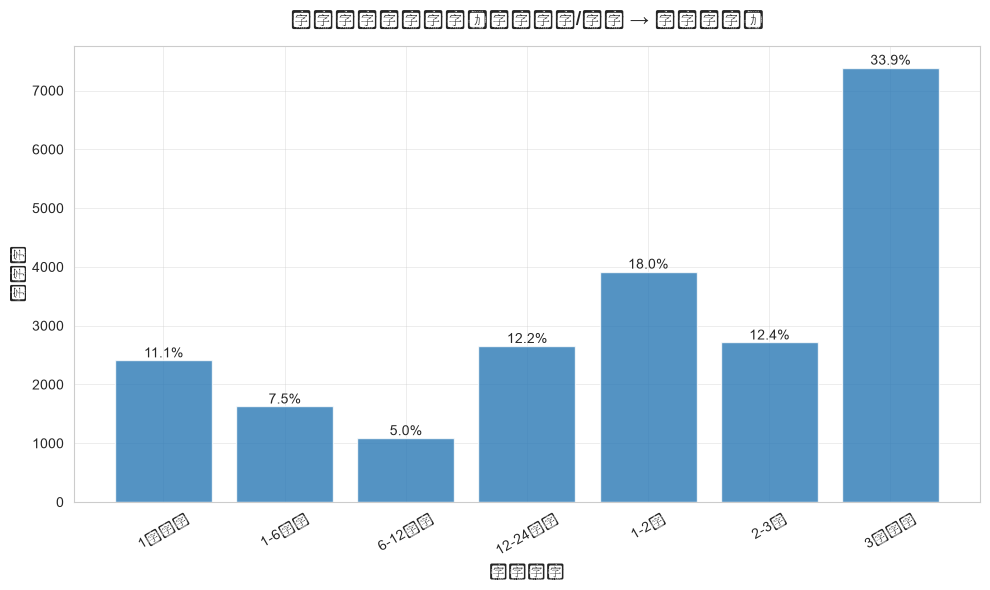

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(period_dist.index, period_dist.values,
              color='#2978B5', alpha=0.8, edgecolor='white')

for bar, pct in zip(bars, period_pct.values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=10)

ax.set_xlabel('决策周期', fontsize=12)
ax.set_ylabel('用户数', fontsize=12)
ax.set_title('购买决策周期分布（首次加购/收藏 → 首次购买）',
             fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig('../data/04_decision_period.png', dpi=150, bbox_inches='tight')
plt.show()